In [1]:
import os
from gym import Env, spaces
import numpy as np
import cv2  
import matplotlib
import matplotlib.pyplot as plt
import random
import open3d as o3d
import trimesh

def load_meshes(folder, simplify_mesh=False):
    meshes = {}
    for f in os.listdir(folder):
        if 'obj' in f:
            #meshes[f] = trimesh.load_mesh(os.path.join(folder,f))
            mesh = o3d.io.read_triangle_mesh(os.path.join(folder,f))
            if simplify_mesh:
                voxel_size = max(mesh.get_max_bound() - mesh.get_min_bound()) / 32
                mesh_smp = mesh.simplify_vertex_clustering(
                    voxel_size=voxel_size,
                    contraction=o3d.geometry.SimplificationContraction.Average)
                meshes[f] = mesh_smp
            else:
                meshes[f] = mesh

    return meshes

def as_mesh(scene_or_mesh):
    """
    Convert a possible scene to a mesh.

    If conversion occurs, the returned mesh has only vertex and face data.
    """
    if isinstance(scene_or_mesh, trimesh.Scene):
        if len(scene_or_mesh.geometry) == 0:
            mesh = None  # empty scene
        else:
            # we lose texture information here
            mesh = trimesh.util.concatenate(
                tuple(trimesh.Trimesh(vertices=g.vertices, faces=g.faces)
                    for g in scene_or_mesh.geometry.values()))
    else:
        assert(isinstance(scene_or_mesh, trimesh.Trimesh))
        mesh = scene_or_mesh
    return mesh

def load_meshes_tri(folder, anatomy_list, simplify_mesh=False, scale=1000):
    meshes = {}
    vertices = []

    for f in os.listdir(folder):
        if 'obj' in f:
            mesh = as_mesh(trimesh.load_mesh(os.path.join(folder,f)))
            mesh.apply_scale(scale)
            if simplify_mesh and 'Belly' not in f:
                mesh = mesh.simplify_quadratic_decimation(2000)
            meshes[f] = mesh
            vertices.append(np.array(mesh.vertices))

    vertices = np.concatenate(vertices,0)

    belly_center = np.array(meshes['Belly.obj'].centroid)
    targets = []
    for k in anatomy_list:
        bb_c = np.array(meshes[k].centroid)
        tgt = bb_c + (belly_center-bb_c)*0.6
        # (sanity) check if target is inside mesh 
        check_contains = []
        for j in anatomy_list:
            check_contains.extend(meshes[j].contains(np.expand_dims(tgt,0)))
            #print(k, j, np.min(np.array(meshes[j].vertices)-tgt))

        assert not np.any(np.array(check_contains))
        targets.append(tgt)
    
    return meshes, vertices, targets



In [2]:
anatomy_list = ['DomeOfBladder.obj', 'Uterus.obj', 'CecumAppendix.obj', 'ColonRight.obj', 
                    'LiverRight.obj', 'Falciform.obj', 'LiverLeft.obj', 'GallBladder.obj', 
                    'HepatoDuodenalLigament.obj', 'Spleen.obj', 'Stomach.obj']

meshes,_,_ = load_meshes_tri('envs/obj',anatomy_list,simplify_mesh=False)

In [3]:
demos = []
for i in os.listdir('demos/davos_data'):
    if 'npy' in i:
        demos.append(np.load(os.path.join('demos/davos_data',i)))

(16189, 21)


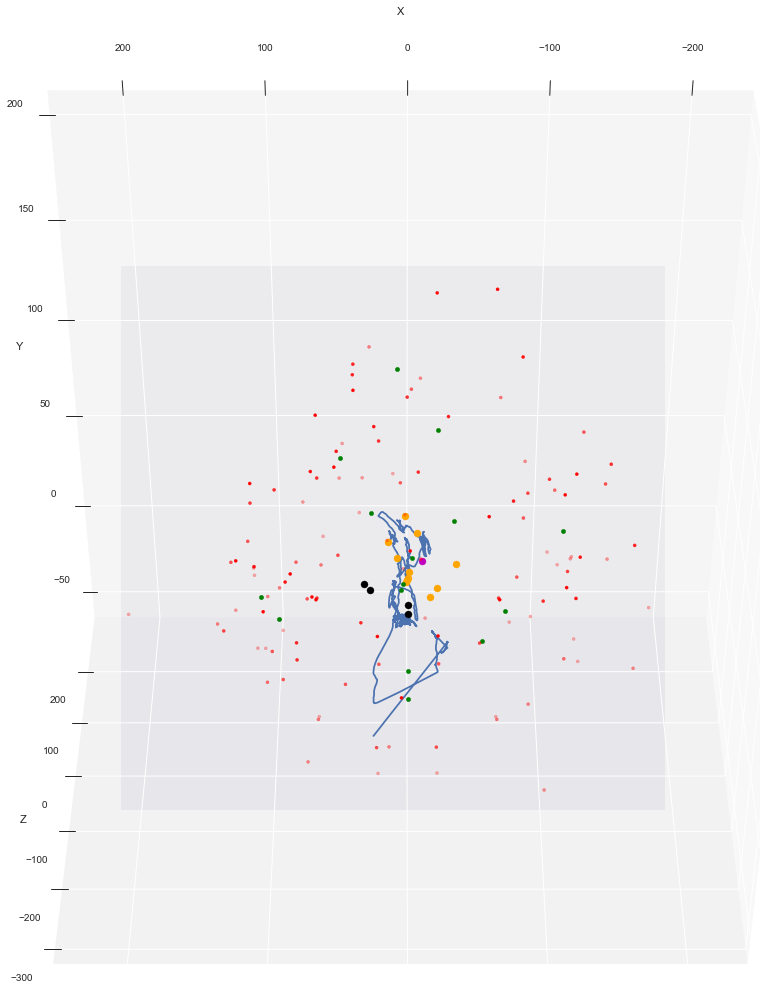

In [4]:
from mpl_toolkits.mplot3d import Axes3D
matplotlib.style.use('seaborn')

fig = plt.figure(figsize=[10,10])
ax = fig.add_subplot(111, projection='3d')
#ax = Axes3D(fig)
idx = np.arange(500,560)

plot_mesh=False
ax.view_init(-50, 90)
ax.dist = 5
total_points = 0
belly_center = np.array(meshes['Belly.obj'].centroid)
scale = 1
scale_demos = 1

for k,v in meshes.items():
    total_points += len(v.vertices)
    vtx = np.array(v.vertices)*scale
    
    #mean_normal = np.mean(np.array(v.vertex_normals),0)
    
    idx = np.arange(int(len(v.vertices)/2)-30, int(len(v.vertices)/2)+30)
    bb = np.array(v.bounding_box_oriented.vertices)*scale
    bb_c = np.array(v.centroid)*scale
    tgt = bb_c + (belly_center-bb_c)*0.7
    if plot_mesh:
        if 'LiverRight' in k:
            ax.scatter(-vtx[:,0],vtx[:,1],-vtx[:,2], s=0.2)
            ax.scatter(-vtx[idx,0],vtx[idx,1],-vtx[idx,2], s=3, c='cyan')
        else:
            ax.scatter(vtx[:,0],vtx[:,1],vtx[:,2], s=0.2)
            ax.scatter(vtx[idx,0],vtx[idx,1],vtx[idx,2], s=3, c='cyan')

    ax.scatter(bb[:,0],bb[:,1],bb[:,2], s=10, c='red')
    ax.scatter(bb_c[0],bb_c[1],bb_c[2], s=20, c='green')
    if 'ColonRight' in k:
        ax.scatter(tgt[0],tgt[1],tgt[2], s=50, c='k')
    elif 'DomeOfBladder' in k:
        ax.scatter(tgt[0],tgt[1],tgt[2], s=50, c='k')
    elif 'Uterus' in k:
        ax.scatter(tgt[0],tgt[1],tgt[2], s=50, c='k')    
    elif 'CecumAppendix' in k:
        ax.scatter(tgt[0],tgt[1],tgt[2], s=50, c='k')    
    elif 'Stomach' in k:
        ax.scatter(tgt[0],tgt[1],tgt[2], s=50, c='m')
    else:
        ax.scatter(tgt[0],tgt[1],tgt[2], s=50, c='orange')

    #ax.text(tgt[0], tgt[0], tgt[0], k, (0.001,0,0), c='orange')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

#demos = demos[0]
print(demos[0].shape)
# splice out pouch of douglas part
selected_demo = demos[0][demos[0][:,-1]!=3] 
ax.plot(selected_demo[20:-100,0], selected_demo[20:-100,1], selected_demo[20:-100,2])


#ax.scatter(vtx[idx,0],vtx[idx,1],vtx[idx,2], s=0.5, c='red')

In [5]:
np.mean(np.array(meshes['LiverRight.obj'].vertex_normals),0)

array([ 0.05947862, -0.02331043,  0.05417574])

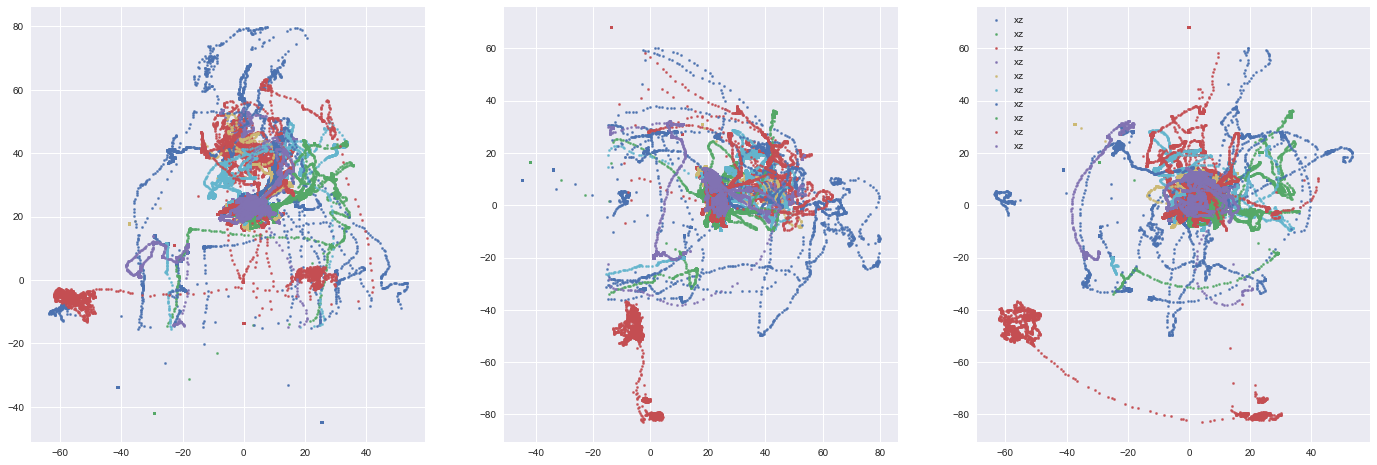

In [22]:
d_ = demos[:10]
offset = 100

f, ax = plt.subplots(1,3,figsize=(24,8))

for d in d_:
    ax[0].scatter(d[offset:,0],d[offset:,1], s=5, label='xy')
    ax[1].scatter(d[offset:,1],d[offset:,2], s=5, label='yz')
    ax[2].scatter(d[offset:,0],d[offset:,2], s=5, label='xz')

plt.legend()